# Solutions · Part 1: What makes these agents different
Answers to the "Try it" exercises. Try them yourself first.

## Lesson 00
Classify each task by the agent kind it needs, then map the kind to the Part that teaches it.

In [1]:
tasks = [
    "Fill in a supplier's web form from a spreadsheet",
    "Upgrade a library and fix every failing test",
    "Build a 40-feature app over three days",
    "Reproduce a bug report by clicking through the app",
]
kinds = ["computer-use", "coding", "long-horizon", "computer-use"]
part_for = {"computer-use": 2, "coding": 3, "long-horizon": 5}
for task, kind in zip(tasks, kinds):
    print(f"{kind:13} Part {part_for[kind]}  {task}")
assert kinds.count("computer-use") == 2

computer-use  Part 2  Fill in a supplier's web form from a spreadsheet
coding        Part 3  Upgrade a library and fix every failing test
long-horizon  Part 5  Build a 40-feature app over three days
computer-use  Part 2  Reproduce a bug report by clicking through the app


## Lesson 01
The environment holds the search function; the check looks only at the environment.

In [2]:
def buggy_search(env, query):
    return [i for i, issue in env["issues"].items() if query in issue["title"]]

def fixed_search(env, query):
    return [i for i, issue in env["issues"].items() if query.lower() in issue["title"].lower()]

def make_env(search, status):
    return {"issues": {1: {"title": "Login page broken", "status": "open"},
                       2: {"title": "Search ignores capital letters", "status": status}},
            "search": search}

def check_issue_2(env):
    problems = []
    if env["issues"][2]["status"] != "closed":
        problems.append("issue #2 is still open")
    if env["search"](env, "SEARCH") != [2]:
        problems.append("search('SEARCH') does not return [2]")
    return problems

print("buggy:", check_issue_2(make_env(buggy_search, "open")))
print("fixed:", check_issue_2(make_env(fixed_search, "closed")))
assert len(check_issue_2(make_env(buggy_search, "open"))) == 2
assert check_issue_2(make_env(fixed_search, "closed")) == []

buggy: ['issue #2 is still open', "search('SEARCH') does not return [2]"]
fixed: []


## Lesson 02
Downscale with Pillow, cost each size with the pixel formula, and compare with the aria snapshot.

1280x960: 1610 tokens = 4.2 aria snapshots
512x384: 266 tokens = 0.7 aria snapshots


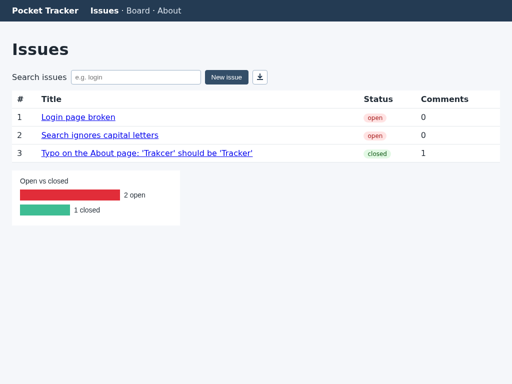

In [3]:
import math, os
from pathlib import Path
from PIL import Image
from IPython.display import display
os.environ["TIKTOKEN_CACHE_DIR"] = "../data/tiktoken_cache"
import tiktoken

def claude_image_tokens(width, height):
    return math.ceil(width / 28) * math.ceil(height / 28)

img = Image.open("../data/02_issues_page.png")
aria_tokens = len(tiktoken.get_encoding("o200k_base").encode(Path("../data/02_issues_page.aria.yaml").read_text()))
for size in [(1280, 960), (512, 384)]:
    tokens = claude_image_tokens(*size)
    print(f"{size[0]}x{size[1]}: {tokens} tokens = {tokens / aria_tokens:.1f} aria snapshots")
small = img.resize((512, 384))
display(small)   # titles are still readable, but small text and the badges get hard to read
assert claude_image_tokens(512, 384) < claude_image_tokens(1280, 960)

## Lesson 03
Rebuild the simulated screen from lesson 03 (with `press` and `check_done` changed from 3 to 4), then mark issue #4 done three ways on a fresh observation. Issue #4 is shown first, so its checkbox is `e2`, and it takes 2 Tabs (search box first).

In [4]:
def new_tracker():
    return {"issues": {
        4: {"title": "Board page is slow", "status": "open", "comments": []},
        1: {"title": "Login page broken", "status": "open", "comments": []},
        2: {"title": "Search ignores capital letters", "status": "open", "comments": []},
        3: {"title": "Typo on the About page: 'Trakcer' should be 'Tracker'", "status": "open", "comments": []}}}

def layout(env):
    elements = [{"role": "searchbox", "name": "Search issues"}]
    for i, issue in env["issues"].items():
        elements.append({"role": "checkbox", "name": f"Mark #{i} done", "issue": i})
        elements.append({"role": "link", "name": issue["title"]})
    return elements

def press(env, ref):
    el = {f"e{n}": el for n, el in enumerate(layout(env), start=1)}[ref]
    if el["role"] == "checkbox":
        issue = env["issues"][el["issue"]]
        issue["status"] = "open" if issue["status"] == "closed" else "closed"

def check_done_4(env, before):   # check_done from the lesson, with 3 changed to 4
    problems = [] if env["issues"][4]["status"] == "closed" else ["issue #4 is not closed"]
    for i, issue in env["issues"].items():
        if i != 4 and issue["status"] != before["issues"][i]["status"]:
            problems.append(f"issue #{i} changed to {issue['status']}")
    return problems

In [5]:
env = new_tracker()   # element ref, read from a fresh snapshot
snapshot = [f'- {el["role"]} "{el["name"]}" [ref=e{n}]' for n, el in enumerate(layout(env), start=1)]
ref = next(line.split("[ref=")[1].rstrip("]") for line in snapshot if '"Mark #4 done"' in line)
press(env, ref)
print("ref", ref, check_done_4(env, new_tracker()))
assert ref == "e2" and not check_done_4(env, new_tracker())

env = new_tracker()   # keys: 2 Tabs (search box, then #4's checkbox), then Space
focus = -1
for key in ["Tab", "Tab", "Space"]:
    if key == "Tab":
        focus += 1
    else:
        press(env, f"e{focus + 1}")
print("keys", check_done_4(env, new_tracker()))
assert not check_done_4(env, new_tracker())

env = new_tracker()   # code action, by id
exec("tracker['issues'][4]['status'] = 'closed'", {"tracker": env})
print("code", check_done_4(env, new_tracker()))
assert not check_done_4(env, new_tracker())

ref e2 []
keys []
code []


## Lesson 04
Solve `p ** 300 = 0.9` for `p`, then check with 1,000 simulated runs. Bonus: the 50% length at that `p`.

In [6]:
import numpy as np

p_needed = 0.9 ** (1 / 300)
rng = np.random.default_rng(seed=4)
simulated = (rng.random((1000, 300)) < p_needed).all(axis=1).mean()
half_length = np.log(0.5) / np.log(p_needed)
print(f"needed step reliability: {p_needed:.5f}")
print(f"simulated 300-step success: {simulated:.1%}")
print(f"50% length at that p: about {half_length:.0f} steps")
assert abs(simulated - 0.9) < 0.03

needed step reliability: 0.99965
simulated 300-step success: 91.6%
50% length at that p: about 1974 steps
